In [1]:
# ==========================================
# TECH CHALLENGE - FASE 1: SUPORTE AO DIAGNÓSTICO
# Tema: Classificação de Câncer de Mama (Maligno vs Benigno)
# ==========================================

# 1. IMPORTAÇÃO DE BIBLIOTECAS (Fundamentos e ML)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_breast_cancer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import (
    GridSearchCV,
    cross_val_score,
    train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

# Configuração para ignorar avisos
import warnings

warnings.filterwarnings('ignore')

In [2]:
# ==========================================
# 2. CARREGAMENTO E EXPLORAÇÃO DOS DADOS
# ==========================================
print('--- 1. CARREGANDO E EXPLORANDO OS DADOS ---')
cancer = load_breast_cancer()
df = pd.DataFrame(cancer.data, columns=cancer.feature_names)
df['target'] = cancer.target  # 0 = Maligno, 1 = Benigno (conforme dataset)

# Visualizando as primeiras linhas
display(df.head())

print(f'Dimensões do dataset: {df.shape}')
print(
    f"Distribuição das classes:\n{df['target'].value_counts().rename({0: 'Maligno (0)', 1: 'Benigno (1)'})}"
)

# Separando variáveis preditoras (X) e alvo (y)
X = df.drop(columns=['target'])
y = df['target']

--- 1. CARREGANDO E EXPLORANDO OS DADOS ---


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


Dimensões do dataset: (569, 31)
Distribuição das classes:
target
Benigno (1)    357
Maligno (0)    212
Name: count, dtype: int64


In [3]:
# ==========================================
# 3. DIVISÃO DOS DADOS (TREINO E TESTE)
# ==========================================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [4]:
# ==========================================
# 4. FEATURE SCALING E PIPELINE (Machine Learning Avançado)
# ==========================================
print('\n--- 2. CRIANDO PIPELINES COM FEATURE SCALING E MODELOS ---')

# Pipeline garante que o scaler seja ajustado apenas no treino para evitar data leakage
pipeline_lr = Pipeline(
    [('scaler', StandardScaler()), ('classifier', LogisticRegression())]
)

pipeline_knn = Pipeline(
    [('scaler', StandardScaler()), ('knn', KNeighborsClassifier(n_neighbors=5))]
)

pipeline_svm = Pipeline(
    [('scaler', StandardScaler()), ('svm', SVC(probability=True, random_state=42))]
)

pipeline_rf = Pipeline(
    [
        (
            'scaler',
            StandardScaler(),
        ),  # Árvores não exigem obrigatoriamente, mas mantém o padrão do pipeline
        ('rf', RandomForestClassifier(random_state=42)),
    ]
)


--- 2. CRIANDO PIPELINES COM FEATURE SCALING E MODELOS ---


In [5]:
# ==========================================
# 5. TREINAMENTO E VALIDAÇÃO CRUZADA
# ==========================================
pipelines = {
    'Regressão Logística': pipeline_lr,
    'KNN': pipeline_knn,
    'SVM': pipeline_svm,
    'Random Forest': pipeline_rf,
}

for name, pipe in pipelines.items():
  # Validação Cruzada (Cross-Validation)
  scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='accuracy')
  print(
      f'[{name}] Acurácia média na Validação Cruzada (CV=5):'
      f' {scores.mean():.4f} (+/- {scores.std():.4f})'
  )

  # Treinamento no conjunto completo de treino
  pipe.fit(X_train, y_train)

[Regressão Logística] Acurácia média na Validação Cruzada (CV=5): 0.9802 (+/- 0.0128)
[KNN] Acurácia média na Validação Cruzada (CV=5): 0.9670 (+/- 0.0209)
[SVM] Acurácia média na Validação Cruzada (CV=5): 0.9714 (+/- 0.0179)
[Random Forest] Acurácia média na Validação Cruzada (CV=5): 0.9538 (+/- 0.0235)



--- 3. AVALIAÇÃO NO CONJUNTO DE TESTE ---

Relatório de Classificação (SVM):
              precision    recall  f1-score   support

     Maligno       0.98      0.98      0.98        42
     Benigno       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114



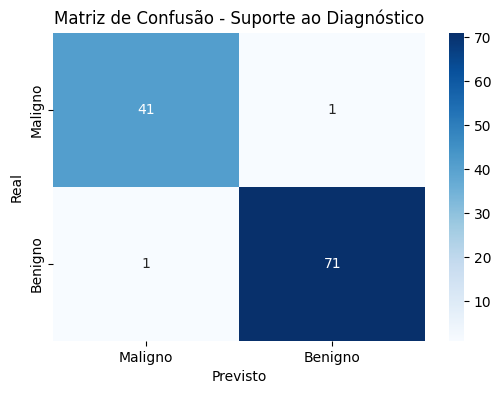

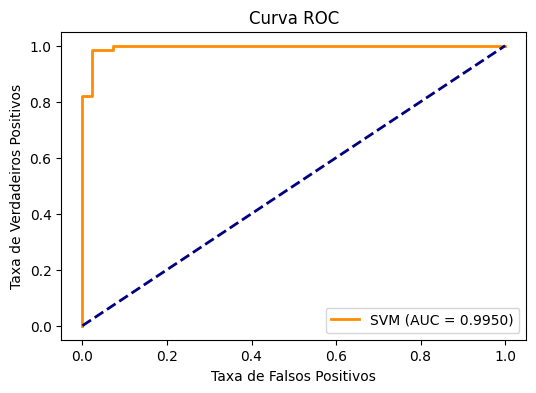

In [6]:
# ==========================================
# 6. AVALIAÇÃO DE MODELOS (Métricas Avançadas)
# ==========================================
print('\n--- 3. AVALIAÇÃO NO CONJUNTO DE TESTE ---')

# Escolhendo o SVM ou Random Forest como destaque (geralmente excelentes para saúde)
best_model = pipeline_svm
y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

# Matriz de Confusão e Classification Report
print('\nRelatório de Classificação (SVM):')
print(classification_report(y_test, y_pred, target_names=['Maligno', 'Benigno']))

# Matriz de Confusão
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Maligno', 'Benigno'],
    yticklabels=['Maligno', 'Benigno'],
)
plt.xlabel('Previsto')
plt.ylabel('Real')
plt.title('Matriz de Confusão - Suporte ao Diagnóstico')
plt.show()

# Curva ROC e AUC Score
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
auc_score = roc_auc_score(y_test, y_prob)

plt.figure(figsize=(6, 4))
plt.plot(
    fpr, tpr, label=f'SVM (AUC = {auc_score:.4f})', color='darkorange', lw=2
)
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlabel('Taxa de Falsos Positivos')
plt.ylabel('Taxa de Verdadeiros Positivos')
plt.title('Curva ROC')
plt.legend(loc='lower right')
plt.show()



--- 4. REDUÇÃO DE DIMENSIONALIDADE COM PCA ---


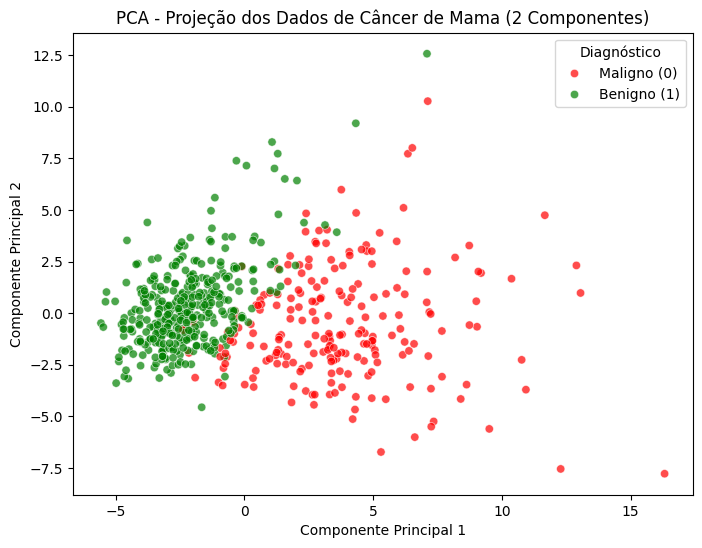

In [8]:
# ==========================================
# 7. REDUÇÃO DE DIMENSIONALIDADE (PCA)
# ==========================================
print('\n--- 4. REDUÇÃO DE DIMENSIONALIDADE COM PCA ---')
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Cria DataFrame auxiliar para plotagem correta
df_pca = pd.DataFrame(X_pca, columns=['Componente 1', 'Componente 2'])
df_pca['Diagnóstico'] = y.map({0: 'Maligno (0)', 1: 'Benigno (1)'})

plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df_pca,
    x='Componente 1',
    y='Componente 2',
    hue='Diagnóstico',
    palette={'Maligno (0)': 'red', 'Benigno (1)': 'green'},
    alpha=0.7,
)

plt.title('PCA - Projeção dos Dados de Câncer de Mama (2 Componentes)')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.show()